In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import math
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, ConcatDataset
from torchvision import datasets, transforms
from IPython.display import clear_output

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

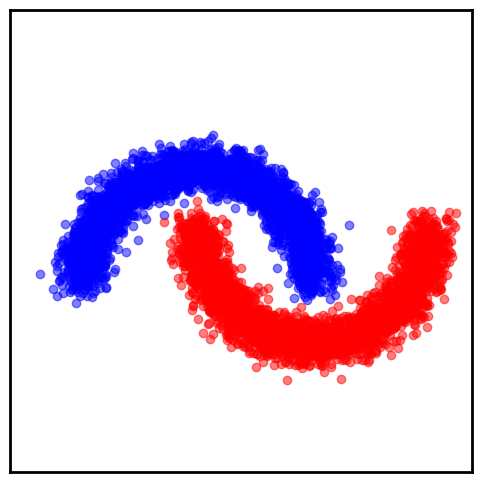

In [120]:
plt.figure(figsize=(6, 6))

plt.scatter(x[:,0][y == 0][:3000], x[:,1][y == 0][:3000], alpha=0.5, color="blue")
plt.scatter(x[:,0][y == 1][:3000], x[:,1][y == 1][:3000], alpha=0.5, color="red")

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

ax = plt.gca()
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(-2.75, 2.75)
ax.set_ylim(-2.75, 2.75)

# Add black border
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(2)

plt.xticks([])
plt.yticks([])

plt.show()

In [20]:
img_size = 28

transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
])

batch_size = 64
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform).data


(-0.5, 139.5, 139.5, -0.5)

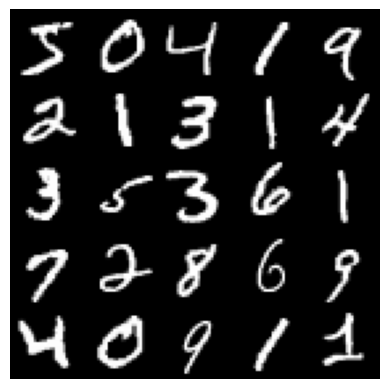

In [110]:
img = torch.tensor([])

for row in train_dataset[:25].split(5):
    img = torch.concat([img, torch.concat([img for img in row], dim=1)])
plt.imshow(img, cmap='gray')
plt.axis('off')

(-0.5, 139.5, 139.5, -0.5)

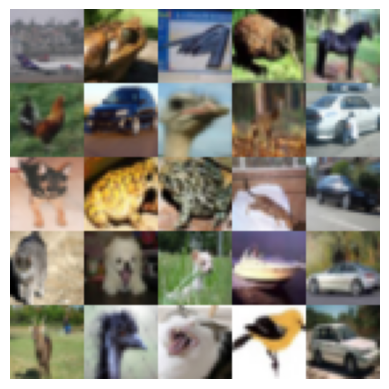

In [109]:
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
])
imgs = torch.stack([transform(img).permute(1,2,0) for img in dataset['train']['img'][:25]])

img = torch.tensor([])

for row in imgs.split(5):
    row = torch.concat([img for img in row], dim=1)
    img = torch.concat([img, row])

plt.imshow(img)
plt.axis('off')

In [16]:
# ---- Your starting lines ----
from datasets import load_dataset
from torch.utils.data import DataLoader
import torch
from torchvision import transforms
dataset = load_dataset("cifar10")

import numpy as np

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

def hf_split_to_torchstyle(hf_split):

    cols = [c.lower() for c in hf_split.column_names]
    if "image" in cols:
        img_col = hf_split.column_names[cols.index("image")]
    elif "img" in cols:
        img_col = hf_split.column_names[cols.index("img")]
    else:
        raise ValueError(f"No image column found. Columns: {hf_split.column_names}")

    images = []
    labels = []

    for item in hf_split:
        img = item[img_col]

        # Convert PIL → numpy if needed
        if hasattr(img, "convert") or hasattr(img, "mode"):
            arr = np.array(img)
        else:
            arr = np.asarray(img)

        images.append(arr)
        labels.append(item["label"])

    images = np.stack(images)   # (N, 32, 32, 3)
    labels = np.array(labels)

    class TorchStyle:
        pass

    t = TorchStyle()
    t.data = images
    t.targets = labels
    return t

train_set = hf_split_to_torchstyle(dataset["train"])
test_set  = hf_split_to_torchstyle(dataset["test"])

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x000001B0EECF2520>>
Traceback (most recent call last):
  File "C:\Users\Sam\anaconda3\envs\UNI_GROUP_PROJECT\lib\site-packages\ipykernel\ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 

KeyboardInterrupt



In [14]:
train_set.data

array([[[[178, 176, 189],
         [178, 176, 189],
         [178, 176, 189],
         ...,
         [170, 168, 180],
         [168, 166, 177],
         [165, 163, 174]],

        [[180, 178, 191],
         [179, 177, 190],
         [180, 178, 191],
         ...,
         [173, 171, 182],
         [171, 169, 180],
         [168, 166, 177]],

        [[177, 175, 188],
         [177, 175, 188],
         [178, 176, 189],
         ...,
         [171, 169, 180],
         [169, 167, 178],
         [167, 165, 176]],

        ...,

        [[112, 107, 107],
         [113, 109, 108],
         [114, 110, 110],
         ...,
         [100,  97,  94],
         [ 98,  94,  93],
         [101,  95,  95]],

        [[112, 102, 101],
         [112, 103, 102],
         [113, 103, 103],
         ...,
         [102,  95,  93],
         [102,  93,  91],
         [102,  92,  91]],

        [[103,  96,  92],
         [100,  93,  90],
         [103,  95,  94],
         ...,
         [ 92,  84,  80],
        